In [1]:
import torch
from torch import nn
from d2l import torch as d2l

### DenseBlock in DenseNet

In below image **[.]** refers to concatenation operation.

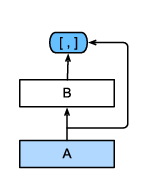

DenseBlock is one of the basic building unit in DenseNet architecture.
DenseNet block uses the modified structure of ResNet "**Batch Normalization, Activation and Convolution**" (**Convolution Block**).

A dense block consist of multiple convolution blocks, each using same number of channels.
In forward propagation the input and output of each convolution block is concatenated along the channel dimension.


The number of convolution blocks channels controls the growth in the number of output channels. This is referred to as **growth rate**.

Eg. Consider a DenseBlock with 2 convolution blocks with channels 10. if the number of input channels is 3 then the total number of output channels are 3 + 10 + 10 = 23.

In [2]:
def conv_block(num_channels):
    return nn.Sequential(
        nn.LazyBatchNorm2d(),
        nn.ReLU(),
        nn.LazyConv2d(num_channels, kernel_size=3, padding=1)
    )


In [7]:
class DenseBlock(nn.Module):
    def __init__(self, num_convs, num_channels):
        super(DenseBlock, self).__init__()
        blk = []

        for _ in range(num_convs):
            blk.append(conv_block(num_channels))
        self.net = nn.Sequential(*blk)

    def forward(self, X):
        for blk in self.net:
            Y = blk(X)
            # Concatenate the input and output along channel dimension
            X = torch.cat((X, Y), dim=1)
        return X

In [8]:
blk = DenseBlock(2, 10)
X = torch.randn(4, 3, 8, 8)
Y = blk(X)
Y.shape

torch.Size([4, 23, 8, 8])

### Transition Layer in DenseNet

Using multiple DenseBlock can easily increase the number of channels. Since number of channels increases then the number of parameters in model also increase which increases the complexity of the model.

To overcome this problem Transition Layer is used. It reduces the number of channels by using 1x1 convolutional layer, followed by average pooling with kernel_size=2 and stride=2.

Transition layer is added between each adjacent DenseBlock. The factor by which the transition layer reduces the number of channels is known as **Compression Factor** (usually set to 0.5)/

In [10]:
def transition_block(num_channels):
    return nn.Sequential(
        nn.LazyBatchNorm2d(),
        nn.ReLU(),
        nn.LazyConv2d(num_channels, kernel_size=1),
        nn.AvgPool2d(kernel_size=2, stride=2)
    )

In [11]:
blk = transition_block(10)
blk(Y).shape

torch.Size([4, 10, 4, 4])

### DenseNet Architecture


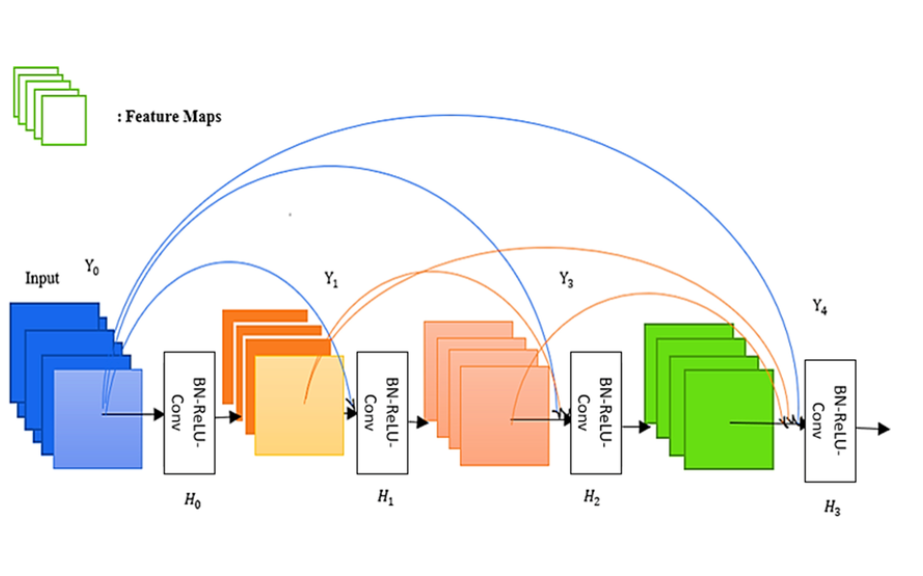

Dense Convolutional Networks (DenseNets) fundamentally alter the residual mapping paradigm. Instead of combining features via element-wise addition ($y = \mathcal{F}(x) + x$), DenseNets combine features via **tensor concatenation**.

The mathematical formulation for the output of the $l$-th layer is:


$$x_l = \mathcal{H}_l([x_0, x_1, \dots, x_{l-1}])$$


where $[x_0, x_1, \dots, x_{l-1}]$ represents the concatenation of the feature maps produced by all preceding layers, and $\mathcal{H}_l$ is a composite operation (typically Batch Normalization $\rightarrow$ ReLU $\rightarrow$ Convolution).

By partitioning the architecture into the Stem, Body, and Head, we can see exactly how DenseNet manages this massive accumulation of feature maps without exploding its parameter count.

### 1. The Stem (Initial Downsampling)

Just like ResNet, DenseNet requires a computational gateway to rapidly compress the spatial dimensions of high-resolution inputs before the heavy tensor concatenation begins.

* **The Operations:** The stem consists of a large $7 \times 7$ convolution with a stride of 2, followed by a $3 \times 3$ Max Pooling layer with a stride of 2.
* **The Dimensionality:** For a $224 \times 224$ RGB image, the stem rapidly downsamples the spatial grid by a factor of 4, outputting a $56 \times 56$ feature map. This prevents the subsequent dense concatenations from immediately overflowing GPU memory.

### 2. The Body (Dense Blocks and Transition Layers)

The body is where the primary hypothesis space is defined. Because continuous concatenation causes the channel depth to grow linearly, the body is divided into two distinct components to manage mathematical complexity.

**A. The Dense Blocks**
Inside a Dense Block, the spatial dimensions (height and width) remain constant, but the channel depth grows with every single layer.

* **The Growth Rate ($k$):** Each $\mathcal{H}_l$ function in the block outputs a strictly small, fixed number of feature maps (e.g., $k = 32$). This parameter $k$ is called the **Growth Rate**.
* **The Math:** If the block receives an input tensor with $C_0$ channels, the $l$-th layer receives exactly $C_0 + k \times (l - 1)$ input channels.
* **The Bottleneck:** To prevent the $3 \times 3$ convolutions from becoming too expensive as the inputs grow, each layer uses a $1 \times 1$ bottleneck convolution to compress the incoming concatenated tensor down to $4k$ channels before the $3 \times 3$ spatial convolution.

**B. The Transition Layers**
If we concatenated features continuously for 100 layers, the channel depth would become computationally lethal. Transition layers are inserted *between* Dense Blocks to act as structural pressure valves.

* **Channel Compression ($\theta$):** A Transition Layer applies a $1 \times 1$ convolution to reduce the number of channels by a compression factor $\theta$ (usually $\theta = 0.5$). If a Dense Block outputs 512 channels, the Transition Layer immediately halves it to 256.
* **Spatial Downsampling:** It then applies a $2 \times 2$ Average Pooling layer with a stride of 2 to halve the spatial dimensions (e.g., $56 \times 56 \rightarrow 28 \times 28$).

### 3. The Head (Classification Projection)

The head takes the extremely deep, feature-rich tensor generated by the final Dense Block and collapses it into the target domain.

* **Global Average Pooling (GAP):** Just like GoogLeNet and ResNet, DenseNet applies GAP to the final spatial grid (typically $7 \times 7$). The spatial features are averaged out, resulting in a single 1D vector.
* **The Linear Classifier:** A single fully connected (Linear) layer maps this vector to the final classification logits.

Because every layer in a Dense Block receives a direct gradient signal from the Head (via the skip-concatenation paths), DenseNets exhibit incredibly strong gradient flow and tend to require significantly fewer parameters than ResNets to achieve the same accuracy.


In [4]:
class DenseNet(d2l.Classifier):
    def __init__(self, num_channels=64, growth_rate=32, arch=(4, 4, 4, 4), lr=0.1, num_classes=10):
        super(DenseNet, self).__init__()
        self.save_hyperparameters()

        self.net = nn.Sequential(
            self.b1()
        )

        for i, num_convs in enumerate(arch):
            self.net.add_module(f'dense_blk{i+1}', DenseBlock(num_convs))
            num_channels += num_convs*growth_rate

            if i!=len(arch)-1:
                num_channels //= 2
                self.net.add_module(f'tran_blk{i+1}', transition_block(num_channels))

        self.net.add_module(f'last', nn.Sequential(
            nn.BatchNorm2d(),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.LazyLinear(num_classes)
        ))

        self.net.apply(d2l.init_cnn)

    def b1(self):
        return nn.Sequential(
            nn.LazyConv2d(64, kernel_size=7, stride=2, padding=3),
            nn.LazyBatchNorm2d(),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, padding=1, stride=2)
        )

In [ ]:
model = DenseNet(lr=0.01)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
trainer.fit(model, data)